# Задача 4.11
# Встреча нескольких лиц с одинаковым ожиданием

## Условие
$n$ человек независимо приходят в течение часа и ждут по $60q$ минут, $0\le q\le1$. Доказать формулу общей встречи, проверить $n=2,3$; при $n=3$ найти вероятность встречи хотя бы двух лиц.

## Теория с нуля и решение вручную
### 1. Общая встреча как размах
Измерим время в долях часа: $X_1,\ldots,X_n$ независимы и равномерны на $[0,1]$. Все одновременно встретятся, если последний придёт раньше ухода первого:
$$\max_iX_i-\min_iX_i\le q.$$
Разность максимума и минимума называется размахом. При одинаковом ожидании именно первый пришедший уходит раньше всех.

### 2. Доказательство формулы
Выберем, кто пришёл первым: $n$ вариантов; совпадения времён имеют вероятность ноль. Пусть его время $t$. Остальные должны попасть в интервал $[t,\min(t+q,1)]$. Для каждого подходящая длина $\min(q,1-t)$, для $n-1$ независимых приходов вероятность равна её степени $n-1$. Интегрируем по первому времени:
$$P_n=n\int_0^1\min(q,1-t)^{n-1}dt=n\left[(1-q)q^{n-1}+\int_{1-q}^1(1-t)^{n-1}dt\right].$$
Последний интеграл $q^n/n$, поэтому
$$P_n=nq^{n-1}-(n-1)q^n.$$
Для $n=2$: $P_2=2q-q^2$, что совпадает с площадью полосы встречи. Для $n=3$: $P_3=3q^2-2q^3$. При $q=1/4$ это $7/16$ и $5/32$.

### 3. Хотя бы два из трёх
Пусть упорядоченные приходы $X_{(1)}<X_{(2)}<X_{(3)}$. Ни одна пара не встретится, если оба соседних промежутка больше $q$. При $q\le1/2$ заменим $Z_1=X_{(1)}$, $Z_2=X_{(2)}-q$, $Z_3=X_{(3)}-2q$. Получим упорядоченные точки в интервале длины $1-2q$. Область масштабируется по всем трём координатам с коэффициентом $1-2q$; отношение объёмов равно $(1-2q)^3$. Значит,
$$P(\text{хотя бы двое})=1-\max(1-2q,0)^3.$$
При $q>1/2$ два соседних промежутка не могут одновременно превышать $q$, ответ 1. При $q=1/4$ ответ $7/8$. «Хотя бы двое» включает встречу всех троих.

### 4. Переход к коду
Так как конкретное $q$ в условии не задано, оно задаётся параметром; для иллюстрации берём $q=1/4$. Формулы доказаны для всего диапазона. Для общей встречи считаем размах, для хотя бы одной пары — минимальный соседний промежуток.

### Как связаны теория и эксперимент

Один опыт — одно полное выполнение условия задачи. Повторяем его независимо $N$ раз. Индикатор $I_k(A)$ равен 1, если событие произошло в опыте $k$, и 0 иначе. Тогда
$$N_A=\sum_{k=1}^{N}I_k(A),\qquad \widehat p_N(A)=\frac{N_A}{N}.$$
По закону больших чисел частота приближается к вероятности при росте числа опытов. Она может колебаться и временно удаляться от ответа: монотонное приближение не обещается. Вероятность — характеристика модели, частота — результат конкретного эксперимента.

Для условной вероятности оставляем только опыты, в которых произошло условие $B$:
$$P(A\mid B)=\frac{P(A\cap B)}{P(B)},\qquad \widehat p(A\mid B)=\frac{N_{A\cap B}}{N_B}.$$
Знаменатель здесь $N_B$, а не общее $N$. Если $N_B=0$, оценка пока не определена.

Приближённая стандартная ошибка частоты равна $\sqrt{\widehat p(1-\widehat p)/m}$, где $m=N$ для обычной вероятности и $m=N_B$ для условной. При достаточно большом числе успехов и неудач ориентировочный 95-процентный интервал имеет вид $\widehat p\pm1.96\sqrt{\widehat p(1-\widehat p)/m}$. Это приближение, а не гарантия для каждого запуска. Для редкого события важен именно ожидаемый счётчик $NP(A)$.

### Что делают библиотеки и общие строки кода

`numpy` хранит результаты опытов в массивах, генерирует случайные числа и считает суммы. Булев массив содержит `True` или `False`; при подсчёте это соответственно 1 и 0. `&` означает «и», `|` — «или», `~` — «не»; каждое сравнение берём в скобки. `axis=1` означает действие внутри строки, то есть внутри одного опыта. Векторные операции повторяют одну и ту же понятную формулу сразу для всех опытов.

`matplotlib.pyplot` рисует график накопленной частоты. Стандартные модули `math` и `fractions` дают элементарные функции, число сочетаний `comb` и точные дроби `Fraction`. Они не выбирают метод решения за нас. В коде используются только эти библиотеки; `scipy` не требуется.

`rng = np.random.default_rng(2026)` создаёт генератор с фиксированным начальным состоянием: повторный запуск даёт тот же эксперимент. Это нужно для воспроизводимости. `rng.random(N)` даёт $N$ независимых равномерных чисел от 0 до 1, а `rng.uniform(a,b,N)` — от $a$ до $b$. Концы непрерывных интервалов имеют вероятность ноль.

Общая функция `report` буквально реализует формулы выше: `np.cumsum` последовательно накапливает единицы, после чего мы делим число успехов на число допустимых опытов. Пунктир — теоретическое значение, если оно известно. На графике показана часть точек для читаемости; в расчёт входят **все** опыты. Интервал выводится только как ориентир точности моделирования.

Общая встреча n=2, q=0.25: успехов 65543, знаменатель 150000
  частота = 0.43695333; ориентир 95%: [0.43444318; 0.43946349]
  теория = 0.43750000; разность = -0.00054667


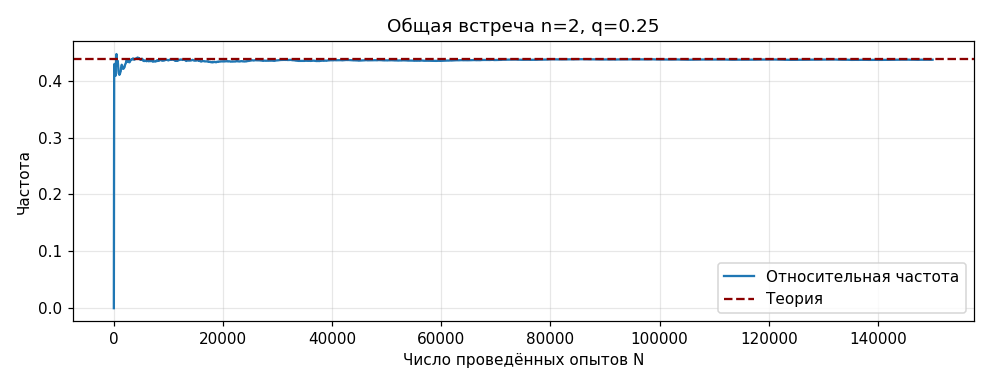

Общая встреча n=3, q=0.25: успехов 23624, знаменатель 150000
  частота = 0.15749333; ориентир 95%: [0.15564990; 0.15933677]
  теория = 0.15625000; разность = +0.00124333


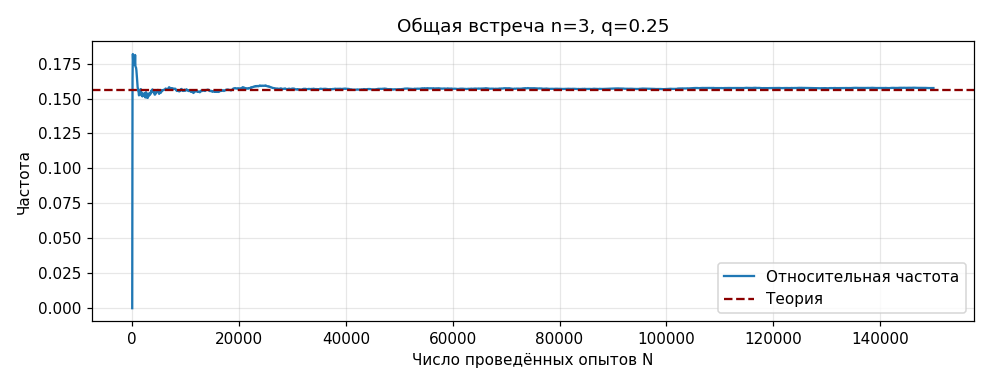

При n=3 встретились хотя бы двое: успехов 131412, знаменатель 150000
  частота = 0.87608000; ориентир 95%: [0.87441255; 0.87774745]
  теория = 0.87500000; разность = +0.00108000


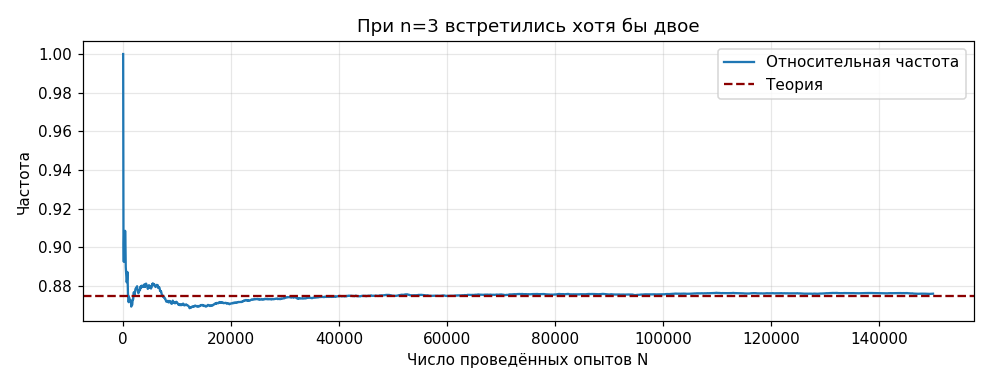

In [1]:
import math
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt

# Начальное состояние генератора фиксируем для повторяемого результата.
rng = np.random.default_rng(2026)

def report(event, name, exact=None, condition=None):
    """Частота события, а при condition — условная частота из теории."""
    event = np.asarray(event, dtype=bool)
    if condition is None:
        condition = np.ones(len(event), dtype=bool)
    # В условном случае считаем успех только вместе с выполнением условия.
    successes = np.cumsum(event & condition)
    eligible = np.cumsum(condition)
    frequency = np.full(len(event), np.nan)
    np.divide(successes, eligible, out=frequency, where=(eligible > 0))
    estimate = frequency[-1]
    m = int(eligible[-1])
    error = math.sqrt(estimate * (1 - estimate) / m) if m else float('nan')
    print(f'{name}: успехов {successes[-1]}, знаменатель {m}')
    print(f'  частота = {estimate:.8f}; ориентир 95%: '
          f'[{max(0, estimate - 1.96 * error):.8f}; '
          f'{min(1, estimate + 1.96 * error):.8f}]')
    if exact is not None:
        print(f'  теория = {float(exact):.8f}; разность = {estimate-float(exact):+.8f}')
    # Накопленные суммы рассчитаны по всем опытам; прореживаем лишь рисунок.
    indices = np.unique(np.linspace(0, len(event)-1, min(2500, len(event))).astype(int))
    plt.figure(figsize=(9, 3.5))
    plt.plot(indices+1, frequency[indices], label='Относительная частота')
    if exact is not None:
        plt.axhline(float(exact), color='darkred', linestyle='--', label='Теория')
    plt.xlabel('Число проведённых опытов N')
    plt.ylabel('Частота')
    plt.title(name)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
    return estimate

N = 150_000
q = 1/4  # Можно изменить на любое число от 0 до 1.
if not 0 <= q <= 1:
    raise ValueError('q должно быть от 0 до 1')
for n in [2, 3]:
    arrivals = np.sort(rng.random((N, n)), axis=1)
    everyone = arrivals[:, -1]-arrivals[:, 0] <= q
    exact = n*q**(n-1)-(n-1)*q**n
    report(everyone, f'Общая встреча n={n}, q={q}', exact)
    if n == 3:
        # Теория 3: ближайшая пара обязательно соседняя в порядке прихода.
        any_pair = np.min(np.diff(arrivals, axis=1), axis=1) <= q
        report(any_pair, 'При n=3 встретились хотя бы двое', 1-max(1-2*q, 0)**3)
